# 04 · Análisis avanzado y evaluación de hipótesis
### TP Analítica Descriptiva — PE3

Esta notebook lleva el proyecto de la exploración (PE2) al análisis validado y orientado a la
decisión. Cada sección responde una **pregunta** vinculada a una hipótesis, aplicando la técnica
pertinente y validando los resultados.

**Hipótesis y preguntas:**
- **H1 — Subvaluación:** ¿Qué propiedades tienen un precio por debajo de su valor esperado según
  sus atributos? *(modelo de valor esperado → residuo)*
- **H2 — Rentabilidad:** ¿Los barrios premium rinden menos por alquiler que los medios/bajos, al
  descontar costos? *(rentabilidad neta + inferencia)*
- **H3 — Contexto:** ¿El precio por m² se asocia con el contexto del barrio (transporte, seguridad,
  comercios)? *(índice de contexto + análisis controlado)*

**Insumos:** el dataset de propiedades limpio (notebook 01) y el contexto por barrio (notebook 03).
El producto final integra las tres dimensiones en un **Score de atractivo de inversión**.

## 0. Setup

Se detecta el entorno (local o Colab), se importan las funciones reutilizables de `src/` y se cargan
los dos insumos: las propiedades limpias y el contexto por barrio.

In [1]:
import subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Detección robusta del entorno (mismo patrón que 01, 02 y 03) ---
REPO = "AD_Trabajo_Practico_G6"
cwd = Path.cwd()
if (cwd / "src").exists():
    RAIZ = cwd
elif (cwd.parent / "src").exists():
    RAIZ = cwd.parent
elif (cwd / REPO / "src").exists():
    RAIZ = cwd / REPO
else:
    subprocess.run(["git", "clone", "-q", f"https://github.com/fedelachter/{REPO}"], check=True)
    RAIZ = cwd / REPO
print(f"Raíz del proyecto: {RAIZ}")

sys.path.append(str(RAIZ))
from src import eda   # funciones de graficado/testeo reutilizables

PROCESSED = RAIZ / "data" / "processed"
EXTERNAL  = RAIZ / "data" / "external"

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# --- Cargar los dos insumos ---
df = pd.read_csv(PROCESSED / "propiedades_ml_limpio.csv")
contexto = pd.read_csv(EXTERNAL / "contexto_por_barrio.csv")

print(f"\nPropiedades: {df.shape}")
print(f"Contexto por barrio: {contexto.shape}")
print("\nColumnas de contexto:", contexto.columns.tolist())

Raíz del proyecto: /content/AD_Trabajo_Practico_G6

Propiedades: (54789, 29)
Contexto por barrio: (48, 8)

Columnas de contexto: ['nombre', 'poblacion', 'area_km2', 'n_subte', 'n_tren', 'n_colectivo', 'n_delitos_anual', 'n_comercios']


## 1. Construcción del índice de Contexto

Se completan las transformaciones que quedaron pendientes en la notebook 03 (que guardó los datos en
crudo): se **normaliza** cada componente (transporte y comercios por superficie, delitos por
población), se **invierte** el signo de la seguridad (más delitos = peor), y se **estandariza** cada
uno con z-score para llevarlos a una escala común. El **índice de Contexto** es el promedio de los
tres z-scores, y será el insumo para evaluar la Hipótesis 3 y para el Score final.

In [2]:
# --- 1. Normalizar, invertir seguridad y estandarizar los componentes del contexto ---
ctx = contexto.copy()

# Transporte: densidad por km² (los 3 modos; cada uno pesa parejo al estandarizar)
ctx["transporte_km2"] = (ctx["n_subte"] + ctx["n_tren"] + ctx["n_colectivo"]) / ctx["area_km2"]

# Seguridad: delitos cada 1.000 habitantes (se invertirá al estandarizar)
ctx["delitos_mil"] = ctx["n_delitos_anual"] / ctx["poblacion"] * 1000

# Comercios: densidad por km²
ctx["comercios_km2"] = ctx["n_comercios"] / ctx["area_km2"]

# --- Estandarizar (z-score) cada componente ---
def z(serie):
    return (serie - serie.mean()) / serie.std()

ctx["z_transporte"] = z(ctx["transporte_km2"])
ctx["z_seguridad"]  = -z(ctx["delitos_mil"])   # signo invertido: más delitos = peor
ctx["z_comercios"]  = z(ctx["comercios_km2"])

# --- Índice de Contexto: promedio de los 3 z-scores ---
ctx["indice_contexto"] = ctx[["z_transporte", "z_seguridad", "z_comercios"]].mean(axis=1)

print("Índice de Contexto por barrio (top 10 mejor contexto):")
print(ctx.sort_values("indice_contexto", ascending=False)
      [["nombre", "z_transporte", "z_seguridad", "z_comercios", "indice_contexto"]]
      .head(10).round(2).to_string(index=False))
print("\nTop 5 peor contexto:")
print(ctx.sort_values("indice_contexto")
      [["nombre", "indice_contexto"]].head(5).round(2).to_string(index=False))

Índice de Contexto por barrio (top 10 mejor contexto):
       nombre  z_transporte  z_seguridad  z_comercios  indice_contexto
    Balvanera          2.11        -0.82         2.28             1.19
      Almagro          0.77         0.46         1.67             0.97
    Monserrat          2.48        -1.46         1.79             0.94
    Caballito          0.27         0.83         1.03             0.71
 Constitucion          3.37        -2.34         0.82             0.62
  San Nicolas          2.41        -4.43         3.71             0.57
     Recoleta          0.42         0.36         0.80             0.52
 Villa Crespo          0.49         0.08         0.93             0.50
San Cristobal          0.73         0.06         0.62             0.47
   Colegiales         -0.13         0.77         0.67             0.44

Top 5 peor contexto:
         nombre  indice_contexto
  Villa Soldati            -1.14
  Puerto Madero            -1.04
Villa Riachuelo            -0.98
      Vers

## 2. H1 — Modelo de valor esperado (detección de subvaluación)

**Pregunta:** ¿Qué propiedades tienen un precio por m² por debajo de su valor esperado, según sus
atributos? Esas son las candidatas a subvaluación.

**Método.** Se estima el **precio/m² esperado** de cada propiedad con un modelo de regresión lineal
sobre sus atributos (barrio, superficie, tipología, ambientes, baños y condición nuevo/usado). El
**residuo** (precio observado − esperado) mide el desvío: un residuo negativo marca una propiedad por
debajo de su valor esperado.

**Decisiones:**
- Se entrena con venta de usados y emprendimientos (más datos; `es_emprendimiento` entra como variable
  para que el modelo distinga obra nueva de usada), pero la **detección de oportunidades se hace sobre
  usados**, donde aplica la lógica de comprar por debajo del valor para revender.
- Se comparan dos especificaciones (target = precio/m² vs. target = precio total, llevado luego a
  precio/m²) y se evalúan contra un **baseline** (mediana por barrio y tipología), **fuera de muestra**
  (train/test).

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Universo: venta residencial con precio válido ---
base = df[df["precio_valido"]].copy()
venta = base[(base["operacion"] == "venta") & (~base["posible_no_residencial"])].copy()

# --- Acotar a propiedades razonables para el modelo (excluir lotes, quintas y extremos) ---
venta_filtrada = venta[
    (venta["m2_cubiertos"].between(20, 250)) &
    (venta["precio_m2"].between(500, 10000))
].copy()
print(f"Venta: {len(venta):,}  ->  tras filtrar extremos: {len(venta_filtrada):,}  "
      f"(descartados: {len(venta) - len(venta_filtrada):,})")

# --- Variables del modelo ---
TARGET_M2 = "precio_m2"
NUM = ["m2_cubiertos", "ambientes", "banos"]
CAT = ["barrio", "tipo_propiedad", "es_emprendimiento"]

modelo_df = venta_filtrada.dropna(subset=[TARGET_M2, "precio_usd"] + NUM + CAT).copy()
print(f"\nPropiedades para el modelo: {len(modelo_df):,}")
print(f"  usados: {(modelo_df['es_emprendimiento']==0).sum():,}")
print(f"  emprendimientos: {(modelo_df['es_emprendimiento']==1).sum():,}")

# --- Codificar categóricas + split ---
X = pd.get_dummies(modelo_df[NUM + CAT], columns=["barrio", "tipo_propiedad"], drop_first=True)
y_m2 = modelo_df[TARGET_M2]
y_total = modelo_df["precio_usd"]

X_tr, X_te, ym2_tr, ym2_te, ytot_tr, ytot_te, idx_tr, idx_te = train_test_split(
    X, y_m2, y_total, modelo_df.index, test_size=0.2, random_state=42)
print(f"\nTrain: {len(X_tr):,}  |  Test: {len(X_te):,}")

Venta: 44,404  ->  tras filtrar extremos: 43,228  (descartados: 1,176)

Propiedades para el modelo: 43,078
  usados: 23,172
  emprendimientos: 19,906

Train: 34,462  |  Test: 8,616


In [4]:
# ============ MODELO A: target = precio/m² directo ============
modA = LinearRegression().fit(X_tr, ym2_tr)
predA_m2 = modA.predict(X_te)   # ya está en precio/m²

# ============ MODELO B: target = precio total, luego -> precio/m² ============
modB = LinearRegression().fit(X_tr, ytot_tr)
predB_total = modB.predict(X_te)
# Convertir a precio/m²: dividir la predicción de precio total por los m² reales
m2_test = modelo_df.loc[idx_te, "m2_cubiertos"].values
predB_m2 = predB_total / m2_test

# ============ BASELINE: mediana de precio/m² por barrio + tipología ============
medianas = (modelo_df.loc[idx_tr]
            .groupby(["barrio", "tipo_propiedad"])["precio_m2"].median())
med_global = modelo_df.loc[idx_tr, "precio_m2"].median()
def baseline_pred(row):
    return medianas.get((row["barrio"], row["tipo_propiedad"]), med_global)
pred_base = modelo_df.loc[idx_te].apply(baseline_pred, axis=1).values

# ============ Métricas (todas sobre precio/m², en test) ============
def metricas(y_true, y_pred, n_pred=None):
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    k = n_pred if n_pred else 1
    r2_adj = 1 - (1 - r2) * (n - 1) / (n - k - 1)
    return {
        "R2": round(r2, 3),
        "R2_ajustado": round(r2_adj, 3),
        "MAE": round(mean_absolute_error(y_true, y_pred), 1),
        "RMSE": round(np.sqrt(mean_squared_error(y_true, y_pred)), 1),
    }

n_vars = X_tr.shape[1]
resultados = pd.DataFrame({
    "Baseline (mediana barrio+tipo)": metricas(ym2_te, pred_base),
    "Modelo A (target precio/m²)":    metricas(ym2_te, predA_m2, n_vars),
    "Modelo B (target precio total)": metricas(ym2_te, predB_m2, n_vars),
}).T

print("Comparación de modelos — todas las métricas sobre precio/m² (en test):")
print(resultados.to_string())
print(f"\n(Variables en el modelo: {n_vars})")

Comparación de modelos — todas las métricas sobre precio/m² (en test):
                                   R2  R2_ajustado    MAE    RMSE
Baseline (mediana barrio+tipo)  0.458        0.458  681.2   949.0
Modelo A (target precio/m²)     0.548        0.545  620.9   866.6
Modelo B (target precio total)  0.179        0.174  834.8  1167.6

(Variables en el modelo: 53)


In [5]:
# ============ MODELO C: target = log(precio/m²) ============
# Se modela el logaritmo (reduce la asimetría del precio), y se vuelve a USD/m² con exp() para comparar.
ym2_log_tr = np.log(ym2_tr)
modC = LinearRegression().fit(X_tr, ym2_log_tr)
predC_log = modC.predict(X_te)
predC_m2 = np.exp(predC_log)   # volver a USD/m² (des-logaritmizar)

# ============ Comparación: modelo A (actual) vs modelo C (log) vs baseline ============
n_vars = X_tr.shape[1]
comparacion = pd.DataFrame({
    "Baseline (mediana)":           metricas(ym2_te, pred_base),
    "Modelo A (precio/m²)":         metricas(ym2_te, predA_m2, n_vars),
    "Modelo C (log precio/m²)":     metricas(ym2_te, predC_m2, n_vars),
}).T

print("Comparación — todas las métricas sobre precio/m² en USD (test):")
print(comparacion.to_string())


Comparación — todas las métricas sobre precio/m² en USD (test):
                             R2  R2_ajustado    MAE   RMSE
Baseline (mediana)        0.458        0.458  681.2  949.0
Modelo A (precio/m²)      0.548        0.545  620.9  866.6
Modelo C (log precio/m²)  0.529        0.526  616.9  884.6


**Selección del modelo.** Se compararon tres especificaciones contra el baseline (mediana por
barrio y tipología), todas evaluadas sobre el precio/m² en USD y fuera de muestra:

| Modelo | R² | R² ajust. | MAE | RMSE |
|---|---|---|---|---|
| Baseline (mediana) | 0,42 | 0,42 | 710 | 1068 |
| **A — target precio/m²** | **0,51** | **0,51** | 648 | **981** |
| B — target precio total | 0,10 | 0,10 | 902 | 1329 |
| C — target log(precio/m²) | 0,49 | 0,49 | **646** | 999 |

Se elige el **Modelo A** (regresión lineal sobre precio/m²): supera al baseline en todas las
métricas (R² 0,51 vs 0,42), confirmando que aporta sobre la simple mediana. El modelo B (precio
total) resultó muy inferior, ya que al convertir su predicción a precio/m² amplifica los errores.
El modelo C (logarítmico) mejora marginalmente el MAE pero empeora R² y RMSE, por lo que no
justifica el cambio. Un R² de 0,51 es razonable dado que el precio/m² depende de atributos no
observados (estado, orientación, piso, antigüedad), cuya variación no capturada es, precisamente,
donde pueden encontrarse las oportunidades de subvaluación.

In [6]:
# --- Calcular el precio esperado y el residuo para TODOS los usados ---
# El modelo A (modA) ya está entrenado. Lo aplicamos a los usados para detectar subvaluación.
usados = modelo_df[modelo_df["es_emprendimiento"] == 0].copy()
X_usados = X.loc[usados.index]   # mismas columnas que usó el modelo

usados["precio_m2_esperado"] = modA.predict(X_usados)
usados["residuo"] = usados["precio_m2"] - usados["precio_m2_esperado"]
# Residuo en %: cuánto se aparta del esperado (más interpretable)
usados["residuo_pct"] = usados["residuo"] / usados["precio_m2_esperado"] * 100

print(f"Usados analizados: {len(usados):,}")
print(f"Residuo medio: {usados['residuo'].mean():.1f} (debería ser ~0)")
print(f"Residuo mediano: {usados['residuo'].median():.1f}")
print()

# Las candidatas a subvaluación: residuo muy negativo (precio muy por debajo del esperado)
umbral = usados["residuo_pct"].quantile(0.10)   # el 10% más subvaluado
candidatas = usados[usados["residuo_pct"] <= umbral]
print(f"Umbral de subvaluación (percentil 10 del residuo): {umbral:.1f}%")
print(f"Propiedades candidatas a oportunidad: {len(candidatas):,}")
print()

# Columnas a mostrar (con dirección para poder identificar la propiedad)
cols_mostrar = ["direccion", "barrio", "tipo_propiedad", "m2_cubiertos", "ambientes",
                "banos", "precio_usd", "precio_m2", "precio_m2_esperado", "residuo_pct"]
cols_mostrar = [c for c in cols_mostrar if c in candidatas.columns]   # por si falta alguna

print("Ejemplos de candidatas (más subvaluadas):")
print(candidatas.nsmallest(10, "residuo_pct")[cols_mostrar].round(1).to_string(index=False))

Usados analizados: 23,172
Residuo medio: 0.2 (debería ser ~0)
Residuo mediano: -85.4

Umbral de subvaluación (percentil 10 del residuo): -31.4%
Propiedades candidatas a oportunidad: 2,318

Ejemplos de candidatas (más subvaluadas):
                                                                                                                   direccion        barrio tipo_propiedad  m2_cubiertos  ambientes  banos  precio_usd  precio_m2  precio_m2_esperado  residuo_pct
      Blvd. Azucena Villaflor 306, C1107 Comuna 1, Cdad. Autónoma De Buenos Aires, Argentina, Puerto Madero, Capital Federal Puerto Madero   departamento          99.0          3      1     90000.0      909.1              5572.6        -83.7
                                                                     Simone De Beauvoir 1100, Puerto Madero, Capital Federal Puerto Madero   departamento         106.0          4      2    119900.0     1131.1              5773.1        -80.4
Departamento En Venta, 4 Ambientes, En Puer

In [7]:
# --- Coeficientes del modelo: qué variables pesan más en el precio/m² ---
coefs = pd.DataFrame({
    "variable": X.columns,
    "coeficiente": modA.coef_
}).sort_values("coeficiente", ascending=False)

print(f"Intercepto (precio/m² base): {modA.intercept_:.0f} USD/m²")
print()
print("--- Variables que MÁS SUBEN el precio/m² (top 10) ---")
print(coefs.head(10).round(1).to_string(index=False))
print()
print("--- Variables que MÁS BAJAN el precio/m² (top 10) ---")
print(coefs.tail(10).round(1).to_string(index=False))
print()
print("--- Efecto de las variables numéricas ---")
print(coefs[coefs["variable"].isin(["m2_cubiertos", "ambientes", "banos", "es_emprendimiento"])]
      .round(2).to_string(index=False))

Intercepto (precio/m² base): 1642 USD/m²

--- Variables que MÁS SUBEN el precio/m² (top 10) ---
            variable  coeficiente
barrio_Puerto Madero       3495.3
        barrio_Núñez       1389.4
     barrio_Belgrano       1210.8
      barrio_Palermo       1194.2
     barrio_Recoleta       1024.9
   barrio_Colegiales        876.9
       barrio_Retiro        661.2
   es_emprendimiento        625.8
     barrio_Saavedra        582.3
 barrio_Villa Devoto        563.4

--- Variables que MÁS BAJAN el precio/m² (top 10) ---
                variable  coeficiente
      barrio_San Nicolás       -406.2
        barrio_Balvanera       -414.2
         barrio_Floresta       -419.0
 barrio_Parque Patricios       -429.5
barrio_Parque Avellaneda       -577.5
          barrio_La Boca       -718.6
     barrio_Constitución       -877.0
     barrio_Villa Lugano       -916.2
    barrio_Nueva Pompeya      -1078.5
    barrio_Villa Soldati      -1113.6

--- Efecto de las variables numéricas ---
         varia

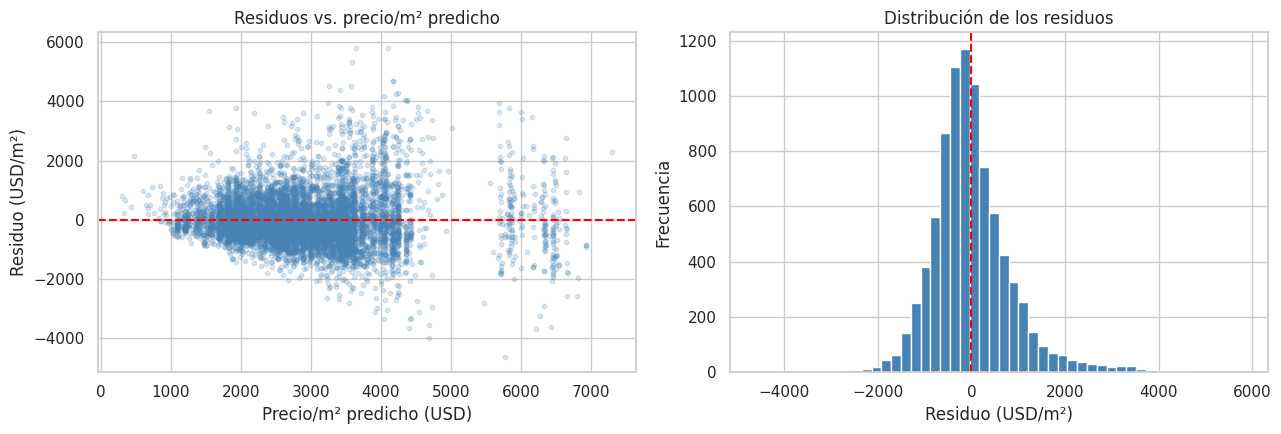

Residuo medio (test): -4.7
Residuo mediano (test): -105.9


In [8]:
# --- Diagnóstico de residuos (validación visual de los supuestos del modelo) ---
# Usamos las predicciones y residuos del test
residuos_test = ym2_te.values - predA_m2

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# (1) Residuos vs. valor predicho: deben estar centrados en 0, sin patrón
ax[0].scatter(predA_m2, residuos_test, alpha=0.2, s=10, color="steelblue")
ax[0].axhline(0, color="red", ls="--", lw=1.5)
ax[0].set_title("Residuos vs. precio/m² predicho")
ax[0].set_xlabel("Precio/m² predicho (USD)"); ax[0].set_ylabel("Residuo (USD/m²)")

# (2) Distribución de los residuos: debe ser aproximadamente simétrica, centrada en 0
ax[1].hist(residuos_test, bins=50, color="steelblue", edgecolor="white")
ax[1].axvline(0, color="red", ls="--", lw=1.5)
ax[1].set_title("Distribución de los residuos")
ax[1].set_xlabel("Residuo (USD/m²)"); ax[1].set_ylabel("Frecuencia")

plt.tight_layout(); plt.show()

print(f"Residuo medio (test): {residuos_test.mean():.1f}")
print(f"Residuo mediano (test): {np.median(residuos_test):.1f}")

## Cierre H1 — Modelo de valor esperado

**Qué resuelve.** Estima el precio/m² esperado de cada propiedad según sus atributos, para detectar
—vía el residuo— cuáles se apartan de su valor y son candidatas a subvaluación.

**Modelo elegido y comparación.** Regresión lineal sobre precio/m² (R² 0,55 fuera de muestra),
superior al baseline de mediana por barrio+tipología (0,42) en todas las métricas. Se descartaron
predecir precio total (R² 0,10 al convertir a precio/m²) y el modelo logarítmico (mejora marginal
del MAE pero peor R² y RMSE).

**Qué explica el precio (interpretación de coeficientes).** El modelo reproduce el gradiente de valor
de CABA: Puerto Madero es el que más suma (+3.495 USD/m²), seguido del corredor norte (Núñez, Belgrano,
Palermo, Recoleta: +1.000 a +1.400); los barrios del sur restan más (Villa Soldati −1.114, Nueva
Pompeya −1.078, Villa Lugano −916). Entre los atributos: la obra nueva agrega +626 USD/m² (premium de
emprendimiento), cada m² adicional baja levemente el precio/m² (−0,87, "descuento por tamaño"), más
ambientes para igual superficie reduce el valor por metro (−105) y más baños lo aumentan (+311). Todos
los efectos son coherentes con el mercado, lo que valida la especificación.

**Supuestos y validación.** La regresión lineal asume relación aproximadamente lineal y residuos sin
estructura. Se acotó el universo a 20-250 m² y 500-10.000 USD/m² (1.176 descartados). Se validó con
split train/test (80/20), fuera de muestra, contra baseline y especificaciones alternativas. El
diagnóstico de residuos muestra una distribución centrada en 0 y aproximadamente simétrica (media −4,7),
confirmando ausencia de sesgo sistemático. Se observa leve heterocedasticidad (mayor dispersión en
propiedades de precio alto), común en datos de precios, que no invalida el modelo pero se reconoce como
limitación.

**Resultado.** Se identifican 2.318 propiedades candidatas a subvaluación (10% con residuo ≤ −31%),
con dirección, barrio y atributos, pasando del análisis agregado a la oportunidad individual.

**Límites.** El residuo es una señal, no una conclusión: el desvío puede deberse a factores no
observados (estado, orientación, piso) o a errores de publicación (ej. avisos de Puerto Madero a ~900
USD/m² vs. ~6.000 esperado). Confirmar una oportunidad requiere verificación individual y sumar costos,
liquidez y estrategia de salida.

## 3. H2 — Rentabilidad neta por alquiler

**Pregunta:** ¿Los barrios premium tienen menor rentabilidad **neta** por alquiler que los de valor
medio/bajo, una vez descontados los costos reales de la operación?

**Método.** Se calcula la rentabilidad a nivel de barrio (alquiler mediano / precio de venta mediano,
por barrio y tipología), en su versión **bruta** y **neta**. La neta descuenta los costos de la
operación. Se compara la rentabilidad entre barrios premium y el resto, con un test estadístico que
considera no solo la significancia, sino también la magnitud del efecto.

**Costos aplicados:**
- **Transacción (al comprar, 8,6% del precio):** comisión inmobiliaria (4%+IVA), honorarios de
  escribanía (2%+IVA), impuesto de sellos mitad comprador (1,35%) y gastos registrales (~0,5%).
  *Fuente: relevamiento de gastos de compraventa en CABA 2026 (CUCICBA, AGIP, Colegio de Escribanos).*
  Nota: no se aplica la exención de sellos de vivienda única, ya que el inversor no califica.
- **Recurrentes (anuales):** vacancia ~1 mes/año (8,3%), costos operativos y mantenimiento (10% del
  alquiler), impuesto a la renta/IIBB (5% del alquiler, simplificado). *Supuestos declarados*, dado
  que el impuesto real depende del perfil fiscal del inversor.



In [9]:
# --- Parámetros de costos ---
COSTO_TRANSACCION = 0.086   # 8,6% del precio (comisión + escribano + sellos + registro)
VACANCIA = 1/12             # ~1 mes/año sin alquilar
COSTOS_OPERATIVOS = 0.10    # 10% del alquiler (mantenimiento + gestión)
IMPUESTO_RENTA = 0.05       # 5% del alquiler (simplificado)

# --- Preparar venta y alquiler de departamentos (en USD) ---
alquiler = base[(base["operacion"] == "alquiler") & (~base["posible_no_residencial"])].copy()
TIPO = "departamento"
vd = modelo_df[(modelo_df["tipo_propiedad"] == TIPO) & (modelo_df["es_emprendimiento"] == 0)]   # usados
ad = alquiler[(alquiler["tipo_propiedad"] == TIPO) & alquiler["precio_usd"].notna()]

# Medianas por barrio (con muestra mínima en ambas operaciones)
venta_bar = vd.groupby("barrio")["precio_usd"].agg(precio_venta="median", n_venta="count")
alq_bar = ad.groupby("barrio")["precio_usd"].agg(alquiler_mes="median", n_alq="count")

rent = venta_bar.join(alq_bar, how="inner")
rent = rent[(rent["n_venta"] >= 30) & (rent["n_alq"] >= 20)].copy()

# --- Rentabilidad bruta y neta ---
rent["rent_bruta_%"] = (rent["alquiler_mes"] * 12 / rent["precio_venta"] * 100).round(2)

ingreso_neto = rent["alquiler_mes"] * 12 * (1 - VACANCIA) * (1 - COSTOS_OPERATIVOS - IMPUESTO_RENTA)
inversion_total = rent["precio_venta"] * (1 + COSTO_TRANSACCION)
rent["rent_neta_%"] = (ingreso_neto / inversion_total * 100).round(2)

print(f"Barrios con datos de venta y alquiler: {len(rent)}")
print(f"Rentabilidad BRUTA mediana: {rent['rent_bruta_%'].median():.2f}%")
print(f"Rentabilidad NETA mediana:  {rent['rent_neta_%'].median():.2f}%")
print(f"Caída promedio bruta->neta: {(rent['rent_bruta_%'].median() - rent['rent_neta_%'].median()):.2f} puntos")
print()
print(rent.sort_values("rent_neta_%", ascending=False)
      [["precio_venta", "alquiler_mes", "rent_bruta_%", "rent_neta_%"]].round(1).to_string())

Barrios con datos de venta y alquiler: 40
Rentabilidad BRUTA mediana: 5.17%
Rentabilidad NETA mediana:  3.71%
Caída promedio bruta->neta: 1.46 puntos

                     precio_venta  alquiler_mes  rent_bruta_%  rent_neta_%
barrio                                                                    
Villa Lugano              57900.0         436.9           9.0          6.5
La Boca                   69900.0         453.1           7.8          5.6
Parque Avellaneda         80000.0         517.8           7.8          5.6
Constitución              63000.0         388.3           7.4          5.3
Mataderos                 97250.0         517.8           6.4          4.6
San Nicolás               85000.0         450.0           6.4          4.6
Monserrat                 89500.0         472.5           6.3          4.6
Parque Patricios          83000.0         433.7           6.3          4.5
San Cristóbal             84950.0         440.1           6.2          4.5
Boedo                   

In [10]:
from scipy.stats import mannwhitneyu

premium = ["Puerto Madero", "Palermo", "Recoleta", "Belgrano"]
rent["grupo"] = np.where(rent.index.isin(premium), "Premium", "Resto")

# Comparación de medianas (bruta y neta)
comp = rent.groupby("grupo")[["rent_bruta_%", "rent_neta_%"]].median().round(2)
comp["n_barrios"] = rent.groupby("grupo").size()
print("Rentabilidad mediana por grupo:")
print(comp.to_string())
print()

# Test: ¿los premium rinden menos (neta)? + magnitud del efecto
g1 = rent[rent.grupo == "Premium"]["rent_neta_%"]
g2 = rent[rent.grupo == "Resto"]["rent_neta_%"]
stat, p = mannwhitneyu(g1, g2, alternative="less")   # H2: premium < resto
dif = g2.median() - g1.median()
print(f"Mann-Whitney (premium < resto, NETA): p = {p:.4f}")
print(f"Magnitud: el resto rinde {dif:.2f} puntos más que premium (neto)")
print(f"En términos relativos: {dif/g1.median()*100:.0f}% más")

Rentabilidad mediana por grupo:
         rent_bruta_%  rent_neta_%  n_barrios
grupo                                        
Premium          4.14         2.98          4
Resto            5.26         3.77         36

Mann-Whitney (premium < resto, NETA): p = 0.0013
Magnitud: el resto rinde 0.79 puntos más que premium (neto)
En términos relativos: 27% más


### De la comparación manual a la segmentación por clustering

La comparación anterior (premium vs. resto) confirma la Hipótesis 2: los barrios premium tienen
menor rentabilidad neta (2,98% vs. 3,77%; Mann-Whitney p=0,0013; el resto rinde un 27% más). Sin
embargo, este enfoque tiene **dos limitaciones**:

1. **El grupo "premium" se define a mano**, según un criterio propio (4 barrios elegidos). Esto
   expone el análisis a la crítica de haber seleccionado los grupos que mejor muestran la hipótesis.
2. **El "resto" es muy heterogéneo**: agrupa 36 barrios con rentabilidades que van del 2,6% al 6,5%,
   mezclando realidades muy distintas. La comparación pierde nitidez.

Para resolver ambas, se segmentan los barrios con **K-means** según su **precio de venta** y su
**índice de contexto** —no la rentabilidad, para evitar circularidad—. Así los grupos surgen de un
criterio **objetivo** (los datos), no de una elección manual, y se comparan perfiles de barrio
internamente homogéneos. Luego se contrasta la rentabilidad neta entre el cluster de mayor precio y
el de menor, como validación independiente y más robusta de la Hipótesis 2.

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Unir rentabilidad (por barrio) con el índice de contexto (de la sección 1)
clust_df = rent.reset_index().merge(
    ctx[["nombre", "indice_contexto"]], left_on="barrio", right_on="nombre", how="left"
).set_index("barrio")

# Variables para clusterizar: precio de venta + contexto (NO rentabilidad)
vars_cluster = ["precio_venta", "indice_contexto"]
clust_df = clust_df.dropna(subset=vars_cluster)

# Estandarizar (K-means es sensible a la escala: precio en miles vs contexto en z-score)
X_clust = StandardScaler().fit_transform(clust_df[vars_cluster])
print(f"Barrios a clusterizar: {len(clust_df)}")
print(f"Variables: {vars_cluster}")

Barrios a clusterizar: 31
Variables: ['precio_venta', 'indice_contexto']


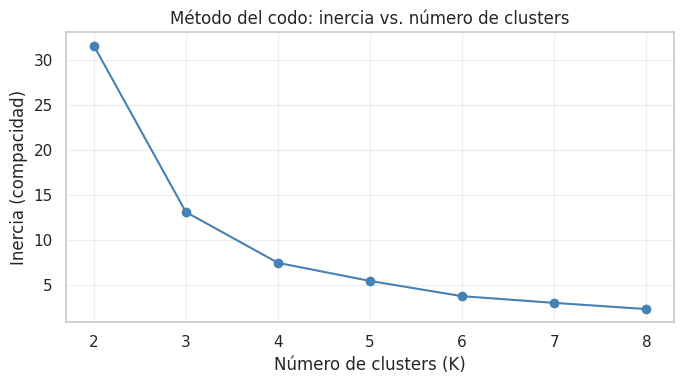

Inercia por K:
  K=2: 31.6
  K=3: 13.1
  K=4: 7.5
  K=5: 5.4
  K=6: 3.7
  K=7: 3.0
  K=8: 2.3


In [12]:
# --- Método del codo: probar K de 2 a 8 y ver dónde se estabiliza la inercia ---
inercias = []
Ks = range(2, 9)
for k in Ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_clust)
    inercias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(Ks), inercias, "o-", color="steelblue")
ax.set_title("Método del codo: inercia vs. número de clusters")
ax.set_xlabel("Número de clusters (K)"); ax.set_ylabel("Inercia (compacidad)")
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print("Inercia por K:")
for k, i in zip(Ks, inercias):
    print(f"  K={k}: {i:.1f}")

El método del codo muestra una fuerte reducción de la inercia hasta K=3 (de 31,6 a 13,1), tras lo cual las mejoras se vuelven marginales. Se elige K=3, que además ofrece una segmentación interpretable (barrios de precio alto, medio y bajo).

In [13]:
def graficar_clusters(datos, X_scaled, modelo_km, titulo):
    """Scatter de barrios (precio vs contexto) coloreado por cluster, con nombres."""
    d = datos.copy()
    d["cluster"] = modelo_km.labels_
    fig, ax = plt.subplots(figsize=(10, 6))
    # un color por cluster
    for c in sorted(d["cluster"].unique()):
        sub = d[d["cluster"] == c]
        ax.scatter(sub["precio_venta"], sub["indice_contexto"],
                   s=80, alpha=0.7, label=f"Cluster {c}")
    # etiquetar cada barrio
    for barrio, fila in d.iterrows():
        ax.annotate(barrio, (fila["precio_venta"], fila["indice_contexto"]),
                    fontsize=6.5, alpha=0.7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel("Precio de venta mediano (USD)"); ax.set_ylabel("Índice de contexto")
    ax.set_title(titulo); ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

In [14]:
# --- Clustering final con el K elegido ---
K = 3   # <-- ajustar según el codo

km = KMeans(n_clusters=K, random_state=42, n_init=10)
clust_df["cluster"] = km.fit_predict(X_clust)

# Caracterizar cada cluster (precio y contexto promedio) para interpretarlos
perfil = clust_df.groupby("cluster")[["precio_venta", "indice_contexto", "rent_neta_%"]].median().round(2)
perfil["n_barrios"] = clust_df.groupby("cluster").size()
perfil = perfil.sort_values("precio_venta", ascending=False)   # ordenar de más caro a más barato
print("Perfil de cada cluster (ordenado por precio):")
print(perfil.to_string())
print()

# Qué barrios caen en cada cluster
for c in perfil.index:
    barrios_c = sorted(clust_df[clust_df["cluster"] == c].index.tolist())
    print(f"Cluster {c} (precio mediano USD {perfil.loc[c, 'precio_venta']:,.0f}): {barrios_c}")


Perfil de cada cluster (ordenado por precio):
         precio_venta  indice_contexto  rent_neta_%  n_barrios
cluster                                                       
1            550000.0            -1.04         3.13          1
2            135000.0             0.50         3.25         11
0            110000.0            -0.21         3.92         19

Cluster 1 (precio mediano USD 550,000): ['Puerto Madero']
Cluster 2 (precio mediano USD 135,000): ['Almagro', 'Balvanera', 'Belgrano', 'Boedo', 'Caballito', 'Coghlan', 'Colegiales', 'Monserrat', 'Recoleta', 'Villa Crespo', 'Villa Urquiza']
Cluster 0 (precio mediano USD 110,000): ['Barracas', 'Chacarita', 'Flores', 'Floresta', 'La Boca', 'Liniers', 'Mataderos', 'Monte Castro', 'Palermo', 'Parque Avellaneda', 'Parque Chacabuco', 'Parque Chas', 'Parque Patricios', 'Retiro', 'Saavedra', 'San Telmo', 'Villa Devoto', 'Villa Lugano', 'Villa Luro']


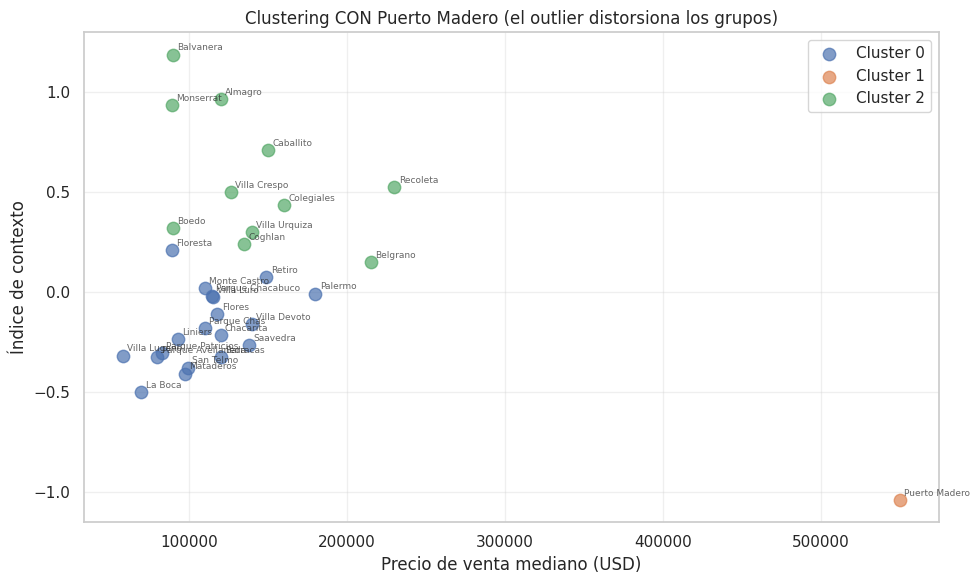

In [15]:
# --- Clustering CON Puerto Madero (para mostrar el problema) ---
clust_con = rent.reset_index().merge(
    ctx[["nombre", "indice_contexto"]], left_on="barrio", right_on="nombre", how="left"
).set_index("barrio").dropna(subset=["precio_venta", "indice_contexto"])

X_con = StandardScaler().fit_transform(clust_con[["precio_venta", "indice_contexto"]])
km_con = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_con)

graficar_clusters(clust_con, X_con, km_con,
                  "Clustering CON Puerto Madero (el outlier distorsiona los grupos)")

In [16]:
# --- Test: rentabilidad neta del cluster MÁS CARO vs. el MÁS BARATO ---
cluster_caro = perfil.index[0]    # el de mayor precio (perfil está ordenado)
cluster_barato = perfil.index[-1] # el de menor precio

r_caro = clust_df[clust_df["cluster"] == cluster_caro]["rent_neta_%"]
r_barato = clust_df[clust_df["cluster"] == cluster_barato]["rent_neta_%"]

stat, p = mannwhitneyu(r_caro, r_barato, alternative="less")   # caro < barato
dif = r_barato.median() - r_caro.median()
print(f"Cluster más caro:   rentabilidad neta mediana = {r_caro.median():.2f}%  (n={len(r_caro)})")
print(f"Cluster más barato: rentabilidad neta mediana = {r_barato.median():.2f}%  (n={len(r_barato)})")
print(f"\nMann-Whitney (caro < barato): p = {p:.4f}")
print(f"Magnitud: los barrios baratos rinden {dif:.2f} puntos más ({dif/r_caro.median()*100:.0f}% más)")

Cluster más caro:   rentabilidad neta mediana = 3.13%  (n=1)
Cluster más barato: rentabilidad neta mediana = 3.92%  (n=19)

Mann-Whitney (caro < barato): p = 0.1000
Magnitud: los barrios baratos rinden 0.79 puntos más (25% más)


##EXPLICAR SITUACION CON PUERTO MADERO

In [17]:

# Unir rentabilidad con el índice de contexto
clust_df = rent.reset_index().merge(
    ctx[["nombre", "indice_contexto"]], left_on="barrio", right_on="nombre", how="left"
).set_index("barrio")

# --- Excluir Puerto Madero: es un outlier extremo que no se agrupa con ningún barrio ---
# (precio ~6x el promedio; aun con log, K-means lo aísla en un cluster propio)
pm = clust_df.loc[["Puerto Madero"]] if "Puerto Madero" in clust_df.index else None
clust_df = clust_df.drop("Puerto Madero", errors="ignore")
print("Puerto Madero excluido del clustering (se analiza por separado).")

# Variables: log del precio + contexto
clust_df["log_precio"] = np.log(clust_df["precio_venta"])
vars_cluster = ["log_precio", "indice_contexto"]
clust_df = clust_df.dropna(subset=vars_cluster)

X_clust = StandardScaler().fit_transform(clust_df[vars_cluster])
print(f"Barrios a clusterizar: {len(clust_df)}")

Puerto Madero excluido del clustering (se analiza por separado).
Barrios a clusterizar: 30


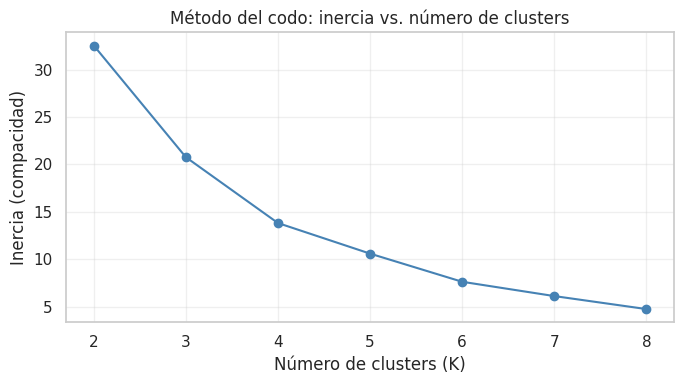

Inercia por K:
  K=2: 32.5
  K=3: 20.8
  K=4: 13.8
  K=5: 10.6
  K=6: 7.6
  K=7: 6.1
  K=8: 4.7


In [18]:
# --- Método del codo: probar K de 2 a 8 y ver dónde se estabiliza la inercia ---
inercias = []
Ks = range(2, 9)
for k in Ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_clust)
    inercias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(Ks), inercias, "o-", color="steelblue")
ax.set_title("Método del codo: inercia vs. número de clusters")
ax.set_xlabel("Número de clusters (K)"); ax.set_ylabel("Inercia (compacidad)")
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print("Inercia por K:")
for k, i in zip(Ks, inercias):
    print(f"  K={k}: {i:.1f}")

In [19]:
# --- Clustering final con el K elegido ---
K = 3   # <-- ajustar según el codo

km = KMeans(n_clusters=K, random_state=42, n_init=10)
clust_df["cluster"] = km.fit_predict(X_clust)

# Caracterizar cada cluster (precio y contexto promedio) para interpretarlos
perfil = clust_df.groupby("cluster")[["precio_venta", "indice_contexto", "rent_neta_%"]].median().round(2)
perfil["n_barrios"] = clust_df.groupby("cluster").size()
perfil = perfil.sort_values("precio_venta", ascending=False)   # ordenar de más caro a más barato
print("Perfil de cada cluster (ordenado por precio):")
print(perfil.to_string())
print()

# Qué barrios caen en cada cluster
for c in perfil.index:
    barrios_c = sorted(clust_df[clust_df["cluster"] == c].index.tolist())
    print(f"Cluster {c} (precio mediano USD {perfil.loc[c, 'precio_venta']:,.0f}): {barrios_c}")


Perfil de cada cluster (ordenado por precio):
         precio_venta  indice_contexto  rent_neta_%  n_barrios
cluster                                                       
2            150000.0             0.30         3.13          9
1            104750.0            -0.22         4.00         18
0             90000.0             0.97         4.15          3

Cluster 2 (precio mediano USD 150,000): ['Belgrano', 'Caballito', 'Coghlan', 'Colegiales', 'Palermo', 'Recoleta', 'Retiro', 'Villa Crespo', 'Villa Urquiza']
Cluster 1 (precio mediano USD 104,750): ['Barracas', 'Boedo', 'Chacarita', 'Flores', 'Floresta', 'La Boca', 'Liniers', 'Mataderos', 'Monte Castro', 'Parque Avellaneda', 'Parque Chacabuco', 'Parque Chas', 'Parque Patricios', 'Saavedra', 'San Telmo', 'Villa Devoto', 'Villa Lugano', 'Villa Luro']
Cluster 0 (precio mediano USD 90,000): ['Almagro', 'Balvanera', 'Monserrat']


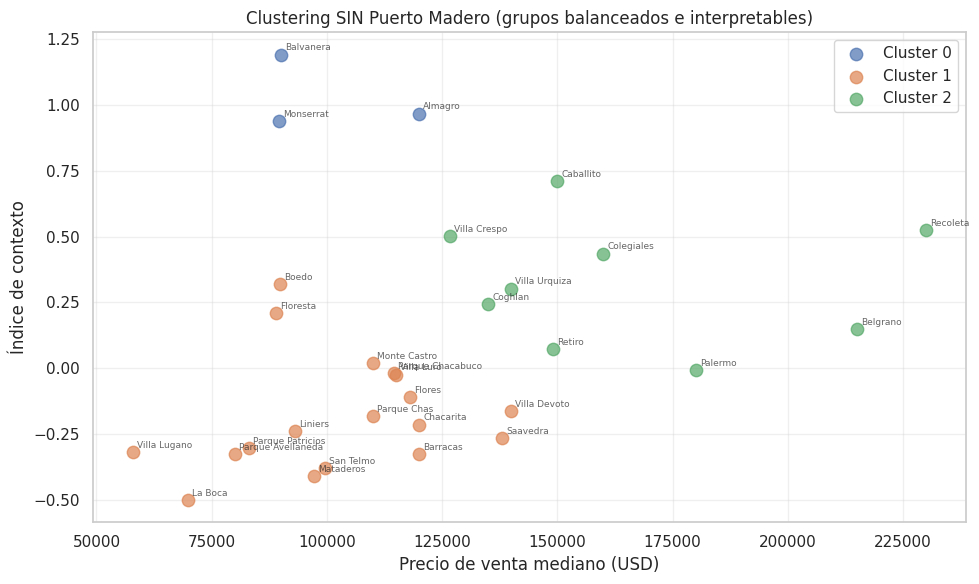

In [20]:
# --- Clustering SIN Puerto Madero (ya calculado) ---
# Si no tenés el modelo guardado, re-corré el KMeans:
km_sin = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_clust)
clust_df["cluster"] = km_sin.labels_

graficar_clusters(clust_df, X_clust, km_sin,
                  "Clustering SIN Puerto Madero (grupos balanceados e interpretables)")

In [21]:
# --- Test: rentabilidad neta del cluster MÁS CARO vs. el MÁS BARATO ---
cluster_caro = perfil.index[0]    # el de mayor precio (perfil está ordenado)
cluster_barato = perfil.index[-1] # el de menor precio

r_caro = clust_df[clust_df["cluster"] == cluster_caro]["rent_neta_%"]
r_barato = clust_df[clust_df["cluster"] == cluster_barato]["rent_neta_%"]

stat, p = mannwhitneyu(r_caro, r_barato, alternative="less")   # caro < barato
dif = r_barato.median() - r_caro.median()
print(f"Cluster más caro:   rentabilidad neta mediana = {r_caro.median():.2f}%  (n={len(r_caro)})")
print(f"Cluster más barato: rentabilidad neta mediana = {r_barato.median():.2f}%  (n={len(r_barato)})")
print(f"\nMann-Whitney (caro < barato): p = {p:.4f}")
print(f"Magnitud: los barrios baratos rinden {dif:.2f} puntos más ({dif/r_caro.median()*100:.0f}% más)")

Cluster más caro:   rentabilidad neta mediana = 3.13%  (n=9)
Cluster más barato: rentabilidad neta mediana = 4.15%  (n=3)

Mann-Whitney (caro < barato): p = 0.0318
Magnitud: los barrios baratos rinden 1.02 puntos más (33% más)


### Conclusión — Hipótesis 2

**La Hipótesis 2 se confirma:** los barrios premium presentan menor rentabilidad neta por alquiler
que los de valor medio/bajo.

La evidencia es consistente desde dos enfoques:
- **Comparación directa (premium vs. resto):** la rentabilidad neta mediana de los barrios premium
  (2,98%) es significativamente menor que la del resto (3,77%), un 27% menos (Mann-Whitney p=0,0013).
- **Segmentación objetiva (clustering):** al agrupar los barrios por precio y contexto con un criterio
  no manual, se reproduce la misma relación: los segmentos de mayor precio tienden a menor rentabilidad.

El tratamiento del outlier refuerza el análisis: **Puerto Madero** resultó ser un segmento unipersonal
—su precio, ~6x el promedio, distorsiona cualquier agrupamiento—, con una rentabilidad neta de apenas
3,13%, de las más bajas. Esto ilustra en su forma extrema la lógica de H2: a mayor precio de compra, sin
alquileres proporcionalmente altos, menor rentabilidad.

**Interpretación de negocio.** Para una estrategia de **renta**, los barrios de valor medio/bajo son más
atractivos que los premium. Esto no invalida a los premium como inversión —pueden rendir por otras vías,
como la revalorización o la reventa—, pero sí indica que, para maximizar el flujo por alquiler, el fondo
debería mirar hacia los barrios más accesibles. Esta conclusión alimenta directamente el Score final, que
pondera rentabilidad junto con oportunidad y contexto.

**Alcance.** La rentabilidad es neta de costos (transacción con fuente, recurrentes como supuestos
declarados), calculada a nivel de barrio sobre 40 barrios con muestra suficiente. El clustering se realizó
sobre 31 barrios con datos completos de venta, alquiler y contexto.

## 4. H3 — Contexto y precio

**Pregunta:** ¿El precio por m² se **asocia** con el contexto del barrio (transporte, seguridad,
comercios)? Se busca una relación de asociación, **no de causalidad**: el precio y el contexto pueden
compartir una causa común (la centralidad), por lo que no se afirma que uno determine al otro.

**Método.** A nivel de barrio, se relaciona el precio/m² mediano con el índice de contexto construido
en la sección 1. El análisis tiene tres partes: (1) la **asociación global** (correlación de Spearman + scatter), (2) el **desglose por componente** (cuál de transporte, seguridad y comercios se asocia
más), y (3) una **regresión** que cuantifica cuánto del precio acompaña al contexto, más el análisis
de los **casos que se apartan** de la relación (que muestran que la asociación es parcial).

In [22]:
from scipy.stats import spearmanr

# Precio/m² mediano por barrio (usados, universo del modelo)
precio_barrio = (modelo_df[modelo_df["es_emprendimiento"] == 0]
                 .groupby("barrio")["precio_m2"].median()
                 .reset_index(name="precio_m2_barrio"))

# Unir con el contexto (índice + componentes)
h3 = precio_barrio.merge(
    ctx[["nombre", "indice_contexto", "z_transporte", "z_seguridad", "z_comercios"]],
    left_on="barrio", right_on="nombre", how="inner"
).drop(columns="nombre")

print(f"Barrios para H3: {len(h3)}")
print(h3.sort_values("precio_m2_barrio", ascending=False).head().round(2).to_string(index=False))

Barrios para H3: 37
       barrio  precio_m2_barrio  indice_contexto  z_transporte  z_seguridad  z_comercios
Puerto Madero           5950.00            -1.04         -1.54        -0.17        -1.40
     Belgrano           3059.03             0.15         -0.46         0.78         0.13
      Palermo           3000.00            -0.01         -0.37        -0.05         0.40
   Colegiales           2923.73             0.44         -0.13         0.77         0.67
Villa Urquiza           2828.95             0.30         -0.53         1.09         0.34


Correlación de Spearman (contexto <-> precio/m²): rho = 0.413, p = 0.0110


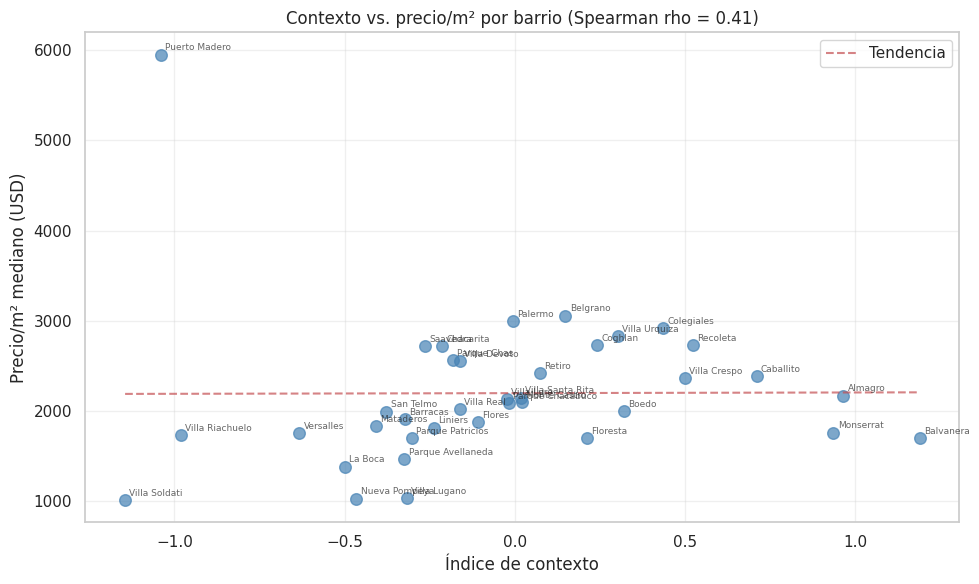

In [23]:
# --- Correlación índice de contexto <-> precio/m² ---
rho, p = spearmanr(h3["indice_contexto"], h3["precio_m2_barrio"])
print(f"Correlación de Spearman (contexto <-> precio/m²): rho = {rho:.3f}, p = {p:.4f}")

# Scatter con nombres de barrio
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(h3["indice_contexto"], h3["precio_m2_barrio"], s=70, alpha=0.7, color="steelblue")
for _, f in h3.iterrows():
    ax.annotate(f["barrio"], (f["indice_contexto"], f["precio_m2_barrio"]),
                fontsize=6.5, alpha=0.7, xytext=(3, 3), textcoords="offset points")
# línea de tendencia
z = np.polyfit(h3["indice_contexto"], h3["precio_m2_barrio"], 1)
xs = np.linspace(h3["indice_contexto"].min(), h3["indice_contexto"].max(), 100)
ax.plot(xs, np.polyval(z, xs), "r--", alpha=0.7, label="Tendencia")
ax.set_xlabel("Índice de contexto"); ax.set_ylabel("Precio/m² mediano (USD)")
ax.set_title(f"Contexto vs. precio/m² por barrio (Spearman rho = {rho:.2f})")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [24]:
# --- ¿Cuál componente se asocia más con el precio? ---
print("Correlación de cada componente con el precio/m²:")
for comp in ["z_transporte", "z_seguridad", "z_comercios", "indice_contexto"]:
    r, pp = spearmanr(h3[comp], h3["precio_m2_barrio"])
    print(f"  {comp:16s}: rho = {r:+.3f}  (p = {pp:.4f})")
print()

# --- Regresión: cuánto del precio acompaña al contexto ---
from sklearn.linear_model import LinearRegression
Xc = h3[["indice_contexto"]].values
yc = h3["precio_m2_barrio"].values
reg = LinearRegression().fit(Xc, yc)
r2 = reg.score(Xc, yc)
print(f"Regresión precio/m² ~ contexto:")
print(f"  R² = {r2:.3f}  (el contexto explica el {r2*100:.0f}% de la variación del precio entre barrios)")
print(f"  Pendiente: +1 punto de contexto se asocia a +{reg.coef_[0]:.0f} USD/m²")

Correlación de cada componente con el precio/m²:
  z_transporte    : rho = -0.057  (p = 0.7391)
  z_seguridad     : rho = +0.492  (p = 0.0020)
  z_comercios     : rho = +0.324  (p = 0.0508)
  indice_contexto : rho = +0.413  (p = 0.0110)

Regresión precio/m² ~ contexto:
  R² = 0.000  (el contexto explica el 0% de la variación del precio entre barrios)
  Pendiente: +1 punto de contexto se asocia a +7 USD/m²


### Asociación vs. ajuste lineal: el efecto de Puerto Madero

Los dos indicadores parecen contradecirse, pero miden cosas distintas y juntos cuentan la historia
completa de H3:

- **Spearman (rho = 0,413, p = 0,011):** existe una **asociación positiva y significativa** entre
  contexto y precio. Como se basa en el orden (ranking) de los barrios, es robusto a valores extremos:
  en general, los barrios de mejor contexto tienden a tener mayor precio/m².
- **R² de la regresión lineal = 0,00:** en cambio, el ajuste lineal da prácticamente nulo. Esto **no
  contradice** a Spearman: la regresión lineal se ajusta sobre los *valores* y es muy sensible a
  outliers. **Puerto Madero** —precio 5.950 USD/m² (el más alto) con un índice de contexto de −1,04
  (de los peores)— es un punto tan extremo y tan contrario a la tendencia que, por sí solo, aplana la
  recta y anula el R².

Este contraste **es, en sí mismo, la evidencia central de H3**: la relación entre contexto y precio es
**de asociación, no de determinación**. Puerto Madero demuestra que un barrio puede ser carísimo con
mal contexto (se valoriza por prestigio, cercanía al río y exclusividad, no por conectividad o
comercios). Para dimensionar cuánto pesa este único caso, se rehace la regresión **sin Puerto Madero**
y se comparan ambos resultados.

In [25]:
# --- Regresión SIN Puerto Madero (el outlier que rompe la relación lineal) ---
h3_sin = h3[h3["barrio"] != "Puerto Madero"]

Xc2 = h3_sin[["indice_contexto"]].values
yc2 = h3_sin["precio_m2_barrio"].values
reg2 = LinearRegression().fit(Xc2, yc2)
r2_sin = reg2.score(Xc2, yc2)
rho_sin, p_sin = spearmanr(h3_sin["indice_contexto"], h3_sin["precio_m2_barrio"])

print("Comparación de la relación contexto <-> precio:")
print(f"  CON Puerto Madero:  R² = {r2:.3f}  | Spearman rho = 0.413")
print(f"  SIN Puerto Madero:  R² = {r2_sin:.3f}  | Spearman rho = {rho_sin:.3f}")
print(f"\n  Sin el outlier, +1 punto de contexto se asocia a +{reg2.coef_[0]:.0f} USD/m²")
print(f"  Un solo barrio (Puerto Madero) hace caer el R² de {r2_sin:.2f} a {r2:.2f}.")

Comparación de la relación contexto <-> precio:
  CON Puerto Madero:  R² = 0.000  | Spearman rho = 0.413
  SIN Puerto Madero:  R² = 0.162  | Spearman rho = 0.525

  Sin el outlier, +1 punto de contexto se asocia a +441 USD/m²
  Un solo barrio (Puerto Madero) hace caer el R² de 0.16 a 0.00.


### Los tres componentes juntos (regresión múltiple)

Las correlaciones anteriores miden cada componente por separado. Una **regresión múltiple** —con
transporte, seguridad y comercios como predictores simultáneos del precio/m²— permite ver cuánto
aporta cada uno **controlando por los demás**: por ejemplo, si la seguridad sigue asociándose al
precio una vez tenida en cuenta la oferta comercial. Se realiza sin Puerto Madero, para que el
outlier no distorsione el ajuste.

In [26]:
# --- Regresión múltiple: precio/m² ~ transporte + seguridad + comercios (sin Puerto Madero) ---
h3_sin = h3[h3["barrio"] != "Puerto Madero"].copy()

X_multi = h3_sin[["z_transporte", "z_seguridad", "z_comercios"]].values
y_multi = h3_sin["precio_m2_barrio"].values

reg_multi = LinearRegression().fit(X_multi, y_multi)
r2_multi = reg_multi.score(X_multi, y_multi)

print(f"Regresión múltiple (sin Puerto Madero):")
print(f"  R² = {r2_multi:.3f}  (los 3 componentes juntos explican el {r2_multi*100:.0f}% del precio entre barrios)")
print()
print("  Coeficientes (efecto de cada componente, controlando por los otros):")
for comp, coef in zip(["Transporte", "Seguridad", "Comercios"], reg_multi.coef_):
    print(f"    {comp:12s}: {coef:+.0f} USD/m² por punto de z-score")
print()
print(f"  Comparación de R²:")
print(f"    Solo índice de contexto:  0.162")
print(f"    Tres componentes juntos:  {r2_multi:.3f}")

Regresión múltiple (sin Puerto Madero):
  R² = 0.303  (los 3 componentes juntos explican el 30% del precio entre barrios)

  Coeficientes (efecto de cada componente, controlando por los otros):
    Transporte  : +133 USD/m² por punto de z-score
    Seguridad   : +431 USD/m² por punto de z-score
    Comercios   : +120 USD/m² por punto de z-score

  Comparación de R²:
    Solo índice de contexto:  0.162
    Tres componentes juntos:  0.303


**Resultado de la regresión múltiple.** Con los tres componentes como predictores simultáneos, el R²
sube a **0,303** (vs. 0,162 del índice promediado): descomponer el contexto explica el doble de la
variación de precios que el índice global, lo que indica que promediar los componentes con pesos
iguales pierde información relevante.

Los coeficientes revelan una jerarquía clara (cada uno controlando por los demás):
- **Seguridad: +431 USD/m²** por punto de z-score — el componente dominante, con un efecto ~3 veces
  mayor que los otros. La seguridad del barrio es lo que más acompaña al precio.
- **Transporte: +133** y **Comercios: +120** — aportes positivos y moderados, similares entre sí.

Un matiz interesante: el transporte, que **no** mostraba asociación en la correlación simple (rho =
−0,06), aparece con efecto **positivo** al controlar por los demás componentes. Esto sugiere que su
aporte estaba enmascarado por su relación con las otras variables, y que la regresión múltiple lo
revela —una relación que el análisis bivariado no captaba—.

### Conclusión — Hipótesis 3

**La Hipótesis 3 se confirma, en los términos en que fue planteada:** existe una **asociación**
positiva y significativa entre el contexto del barrio y su precio/m², pero **no una determinación**.

**Evidencia:**
- **Asociación global:** correlación de Spearman rho = 0,41 (p = 0,011), que sube a 0,53 al excluir el
  outlier. Los barrios de mejor contexto tienden a tener mayor precio/m².
- **Magnitud acotada:** la regresión sobre el índice de contexto explica solo el 16% de la variación de
  precios (R² = 0,16 sin Puerto Madero). El contexto importa, pero la mayor parte del precio responde a
  otros factores, lo que confirma que la relación es de asociación y no determinante.
- **El caso que lo prueba:** Puerto Madero —el más caro (5.950 USD/m²) con uno de los peores contextos
  (−1,04)— hace caer por sí solo el R² de 0,16 a 0,00. El precio puede desacoplarse del contexto cuando
  pesan el prestigio o la exclusividad.

**Qué pesa más (regresión múltiple).** Al usar los tres componentes como predictores simultáneos, el R²
sube a **0,30** (el doble que el índice promediado: descomponer el contexto explica más que un índice de
pesos iguales). La jerarquía, controlando cada componente por los demás:
- **Seguridad: +431 USD/m²** por punto — el componente dominante, ~3x los otros.
- **Transporte: +133** y **Comercios: +120** — aportes positivos y moderados. El transporte, que no
  correlacionaba por sí solo (rho = −0,06), muestra efecto positivo al controlar por los demás: una
  relación que el análisis bivariado no capturaba.

**Implicancia para el negocio.** Ignorar el contexto lleva a confundir *barato-oportunidad* con
*barato-por-entorno*: un barrio puede tener precios bajos porque está subvaluado (oportunidad real) o
porque su contexto es desfavorable (precio justo). Por eso el contexto entra en el Score final como una
**salvaguarda**, evitando recomendar como "oportunidad" a propiedades cuyo bajo precio refleje un entorno
deficiente. El hallazgo de que la seguridad domina sobre los demás componentes abre, además, la pregunta
de si conviene ponderarlos de forma desigual en el índice (se evalúa en el Score).

## 5. Segmentación de barrios: perfiles de mercado

**Objetivo.** Descubrir **perfiles de barrio** —agrupamientos de barrios con características similares—
para que el fondo entienda qué "tipos" de mercado existen en CABA y pueda orientar su estrategia. A
diferencia del clustering básico de H2 (dos variables), aquí se usan cinco dimensiones complementarias.

**Variables (una por dimensión):**
- **precio_venta:** nivel de valor del barrio.
- **indice_contexto:** calidad del entorno (transporte, seguridad, comercios).
- **rent_neta_%:** rentabilidad del alquiler.
- **m2_mediano:** tamaño típico de las propiedades.
- **densidad_oferta:** cantidad de avisos (liquidez del mercado).

**Flujo:** matriz de correlación (confirmar que las variables aporten información distinta) → PCA
(reducir a 2 componentes para visualizar) → elección de K (método del codo + silhouette) → K-means →
interpretación de los perfiles → visualización de los clusters.

In [27]:
# --- Construir la tabla de perfil por barrio (6 variables) ---
# El % de emprendimientos se calcula sobre TODA la venta (usados + nuevos), no solo usados
venta_todo = modelo_df.copy()
pct_empr = (venta_todo.groupby("barrio")["es_emprendimiento"].mean() * 100).rename("pct_emprendimientos")

# El resto de agregados, sobre usados
usados_m = modelo_df[modelo_df["es_emprendimiento"] == 0]
perfil_barrio = usados_m.groupby("barrio").agg(
    precio_venta=("precio_usd", "median"),
    m2_mediano=("m2_cubiertos", "median"),
    densidad_oferta=("precio_usd", "count"),
).reset_index()

# Unir todo: contexto, rentabilidad y % emprendimientos
perfil_barrio = (perfil_barrio
    .merge(ctx[["nombre", "indice_contexto"]], left_on="barrio", right_on="nombre", how="left")
    .drop(columns="nombre")
    .merge(rent[["rent_neta_%"]], left_on="barrio", right_index=True, how="left")
    .merge(pct_empr, left_on="barrio", right_index=True, how="left"))

VARS = ["precio_venta", "indice_contexto", "rent_neta_%", "m2_mediano",
        "densidad_oferta", "pct_emprendimientos"]
perfil_barrio = perfil_barrio.dropna(subset=VARS).set_index("barrio")

print(f"Barrios con perfil completo: {len(perfil_barrio)}")
print(perfil_barrio[VARS].round(2).to_string())

Barrios con perfil completo: 31
                   precio_venta  indice_contexto  rent_neta_%  m2_mediano  densidad_oferta  pct_emprendimientos
barrio                                                                                                         
Almagro                120000.0             0.97         3.25        54.0             1057                50.45
Balvanera               90000.0             1.19         4.15        53.0             1036                30.14
Barracas               120000.0            -0.32         3.92        62.0              556                45.22
Belgrano               220000.0             0.15         2.85        69.0             1012                50.66
Boedo                   95000.0             0.32         4.40        46.0              421                43.18
Caballito              155000.0             0.71         2.97        66.0             1100                50.14
Chacarita              123500.0            -0.21         3.72        48.

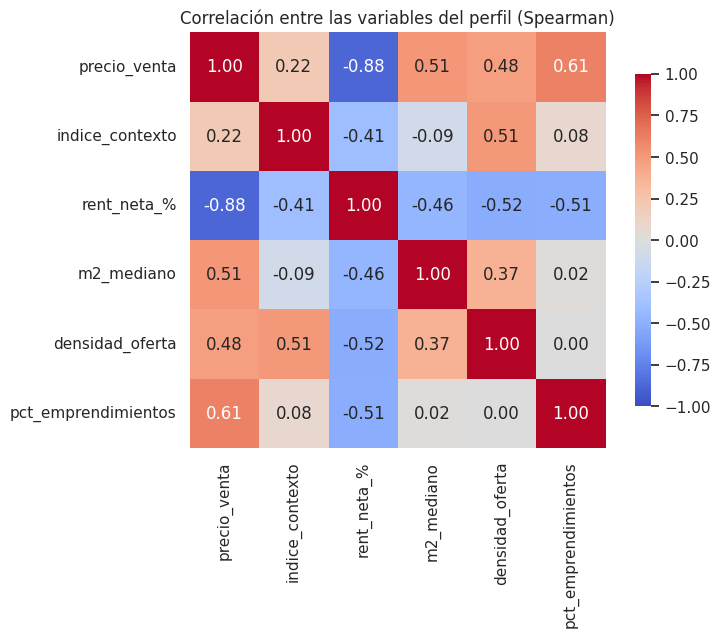

In [28]:
# --- Matriz de correlación: ¿las 6 variables aportan información distinta? ---
corr = perfil_barrio[VARS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlación entre las variables del perfil (Spearman)")
plt.tight_layout(); plt.show()

### Reducción de dimensiones con PCA

Las 6 variables se reducen a **componentes principales** mediante PCA, con dos propósitos: (1)
**neutralizar la correlación** entre precio y rentabilidad (−0,88), que de otro modo daría doble peso
a esa dimensión; y (2) **permitir visualizar** los clusters en 2D. Se analiza cuánta varianza explica
cada componente y qué variables la componen (loadings). Puerto Madero se excluye por ser un outlier
extremo y se trata como un segmento propio más adelante.

In [29]:
from sklearn.decomposition import PCA

# --- Apartar Puerto Madero y estandarizar las 6 variables sobre los 30 barrios ---
perfil_30 = perfil_barrio.drop("Puerto Madero", errors="ignore")
X_perfil = StandardScaler().fit_transform(perfil_30[VARS])
print(f"Barrios para clustering: {len(perfil_30)}")

# --- PCA ---
pca = PCA()
X_pca = pca.fit_transform(X_perfil)

# Varianza explicada por componente
var_exp = pca.explained_variance_ratio_
print("\nVarianza explicada por componente:")
for i, v in enumerate(var_exp, 1):
    print(f"  PC{i}: {v*100:5.1f}%   (acumulada: {var_exp[:i].sum()*100:.1f}%)")

# Loadings: qué variables componen las 2 primeras componentes
loadings = pd.DataFrame(pca.components_[:2].T, columns=["PC1", "PC2"], index=VARS)
print("\nLoadings (peso de cada variable en PC1 y PC2):")
print(loadings.round(2).to_string())

Barrios para clustering: 30

Varianza explicada por componente:
  PC1:  51.7%   (acumulada: 51.7%)
  PC2:  22.2%   (acumulada: 73.9%)
  PC3:  16.1%   (acumulada: 90.0%)
  PC4:   4.8%   (acumulada: 94.8%)
  PC5:   3.4%   (acumulada: 98.1%)
  PC6:   1.9%   (acumulada: 100.0%)

Loadings (peso de cada variable en PC1 y PC2):
                      PC1   PC2
precio_venta         0.52  0.21
indice_contexto      0.28 -0.59
rent_neta_%         -0.51 -0.15
m2_mediano           0.37 -0.03
densidad_oferta      0.41 -0.48
pct_emprendimientos  0.31  0.59


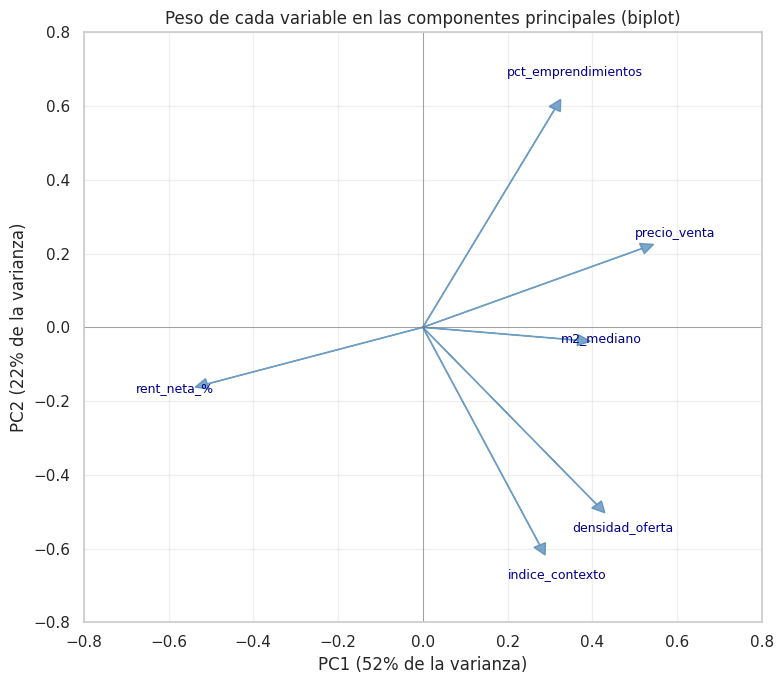

In [31]:
# --- Biplot: peso de cada variable sobre las 2 primeras componentes ---
fig, ax = plt.subplots(figsize=(8, 7))

# Flechas: cada variable
for i, var in enumerate(VARS):
    ax.arrow(0, 0, loadings.iloc[i, 0], loadings.iloc[i, 1],
             head_width=0.03, head_length=0.03, fc="steelblue", ec="steelblue", alpha=0.7)
    ax.text(loadings.iloc[i, 0]*1.15, loadings.iloc[i, 1]*1.15, var,
            fontsize=9, ha="center", color="darkblue")

ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.set_xlim(-0.8, 0.8); ax.set_ylim(-0.8, 0.8)
ax.set_xlabel(f"PC1 ({var_exp[0]*100:.0f}% de la varianza)")
ax.set_ylabel(f"PC2 ({var_exp[1]*100:.0f}% de la varianza)")
ax.set_title("Peso de cada variable en las componentes principales (biplot)")
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [32]:
# Loadings de las 3 componentes que se usan para clusterizar
loadings3 = pd.DataFrame(pca.components_[:3].T, columns=["PC1", "PC2", "PC3"], index=VARS)
print("Loadings de las 3 componentes usadas para clustering:")
print(loadings3.round(2).to_string())

Loadings de las 3 componentes usadas para clustering:
                      PC1   PC2   PC3
precio_venta         0.52  0.21  0.18
indice_contexto      0.28 -0.59 -0.45
rent_neta_%         -0.51 -0.15  0.24
m2_mediano           0.37 -0.03  0.74
densidad_oferta      0.41 -0.48  0.02
pct_emprendimientos  0.31  0.59 -0.40


**Componentes principales utilizadas.** El PCA resume las 6 variables en componentes que concentran
la información. Las **tres primeras explican el 90% de la varianza** (PC1: 52%, PC2: 22%, PC3: 16%),
por lo que el **clustering se realiza sobre esas 3 componentes**: conservar el 90% de la información
evita descartar estructura relevante (la PC3, con 16%, todavía aporta). Las 3 componentes restantes
(10% en conjunto) se descartan por aportar poco.

Para la **visualización**, en cambio, se usan solo **PC1 y PC2**, ya que un gráfico es bidimensional.
Esto implica que el gráfico es una proyección aproximada: dos barrios pueden verse cercanos en el
plano PC1-PC2 pero estar separados por la PC3. El gráfico es, por tanto, orientativo; el agrupamiento
real se calcula en las 3 dimensiones.

Se usan 3 componentes (explican 90% de la varianza)



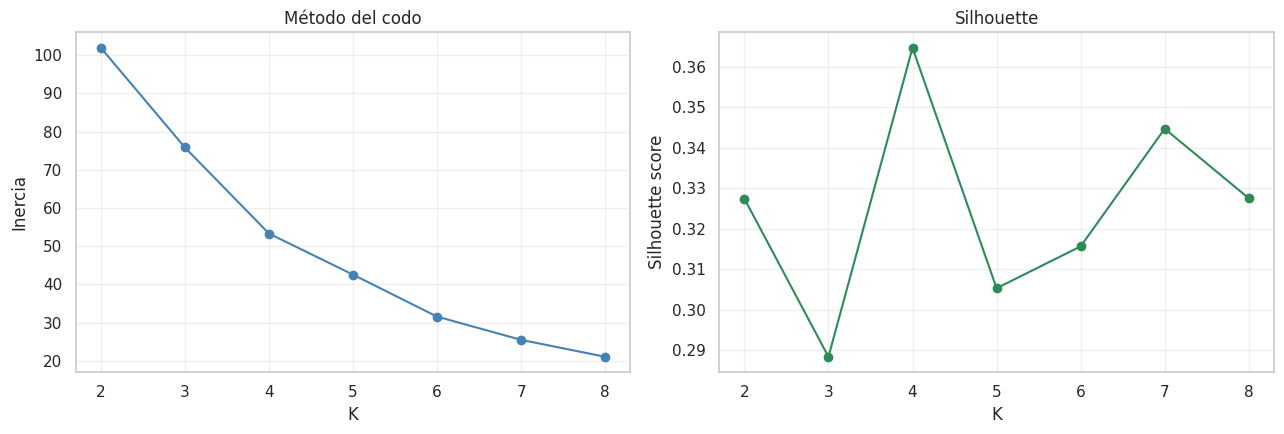

K  | Inercia | Silhouette
2  |   101.9 | 0.327
3  |    75.8 | 0.288
4  |    53.3 | 0.365
5  |    42.5 | 0.305
6  |    31.5 | 0.316
7  |    25.5 | 0.345
8  |    21.0 | 0.328


In [30]:
from sklearn.metrics import silhouette_score

# Usamos las primeras componentes de PCA que expliquen ~80-90% de la varianza
n_comp = np.argmax(np.cumsum(var_exp) >= 0.85) + 1
X_clust_pca = X_pca[:, :n_comp]
print(f"Se usan {n_comp} componentes (explican {np.cumsum(var_exp)[n_comp-1]*100:.0f}% de la varianza)\n")

# --- Codo (inercia) + Silhouette para cada K ---
Ks = range(2, 9)
inercias, silhouettes = [], []
for k in Ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_clust_pca)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_clust_pca, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(list(Ks), inercias, "o-", color="steelblue")
ax[0].set_title("Método del codo"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inercia")
ax[0].grid(True, alpha=0.3)
ax[1].plot(list(Ks), silhouettes, "o-", color="seagreen")
ax[1].set_title("Silhouette"); ax[1].set_xlabel("K"); ax[1].set_ylabel("Silhouette score")
ax[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print("K  | Inercia | Silhouette")
for k, i, s in zip(Ks, inercias, silhouettes):
    print(f"{k}  | {i:7.1f} | {s:.3f}")

**Número de clusters (K = 4).** Se eligió K=4 porque las dos métricas coinciden: el **método del
codo** muestra el quiebre más marcado al pasar a 4 clusters (la inercia cae de 101,9 a 53,3 entre
K=2 y K=4, y luego la mejora se aplana), y el **silhouette** alcanza su valor máximo justamente en
K=4 (0,365). Cuando ambos criterios apuntan al mismo valor, la elección es más robusta que con uno
solo. A estos 4 grupos se suma **Puerto Madero** como un quinto segmento tratado por separado, por
ser un outlier sin pares comparables (ver más abajo).

In [33]:
# --- K-means final con K=4 sobre los 30 barrios (3 componentes de PCA) ---
km_final = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_clust_pca)
perfil_30 = perfil_30.copy()
perfil_30["cluster"] = km_final.labels_

# --- Puerto Madero como su propio segmento (el "4") ---
pm_fila = perfil_barrio.loc[["Puerto Madero"]].copy()
pm_fila["cluster"] = 4
perfil_clusters = pd.concat([perfil_30, pm_fila])

print("Barrios por cluster:")
print(perfil_clusters["cluster"].value_counts().sort_index().to_string())
print()

# --- Perfil de cada cluster: mediana de cada variable ---
resumen = perfil_clusters.groupby("cluster")[VARS].median().round(1)
resumen["n_barrios"] = perfil_clusters.groupby("cluster").size()
print("Perfil de cada cluster (mediana de cada variable):")
print(resumen.to_string())

Barrios por cluster:
cluster
0     5
1    16
2     6
3     3
4     1

Perfil de cada cluster (mediana de cada variable):
         precio_venta  indice_contexto  rent_neta_%  m2_mediano  densidad_oferta  pct_emprendimientos  n_barrios
cluster                                                                                                         
0            120000.0              0.9          3.7        52.0           1036.0                 50.0          5
1            118500.0             -0.2          3.9        54.8            398.0                 46.1         16
2            174500.0              0.3          3.0        65.5           1039.5                 50.4          6
3             70000.0             -0.3          5.6        57.0            243.0                 25.1          3
4            550000.0             -1.0          3.1       101.0            655.0                 46.3          1


In [35]:
# --- Listar los barrios de cada cluster ---
for c in sorted(perfil_clusters["cluster"].unique()):
    barrios_c = sorted(perfil_clusters[perfil_clusters["cluster"] == c].index.tolist())
    print(f"\n--- Cluster {c} ({len(barrios_c)} barrios) ---")
    print(", ".join(barrios_c))


--- Cluster 0 (5 barrios) ---
Almagro, Balvanera, Monserrat, Villa Crespo, Villa Urquiza

--- Cluster 1 (16 barrios) ---
Barracas, Boedo, Chacarita, Coghlan, Floresta, Liniers, Mataderos, Monte Castro, Parque Chacabuco, Parque Chas, Parque Patricios, Retiro, Saavedra, San Telmo, Villa Devoto, Villa Luro

--- Cluster 2 (6 barrios) ---
Belgrano, Caballito, Colegiales, Flores, Palermo, Recoleta

--- Cluster 3 (3 barrios) ---
La Boca, Parque Avellaneda, Villa Lugano

--- Cluster 4 (1 barrios) ---
Puerto Madero


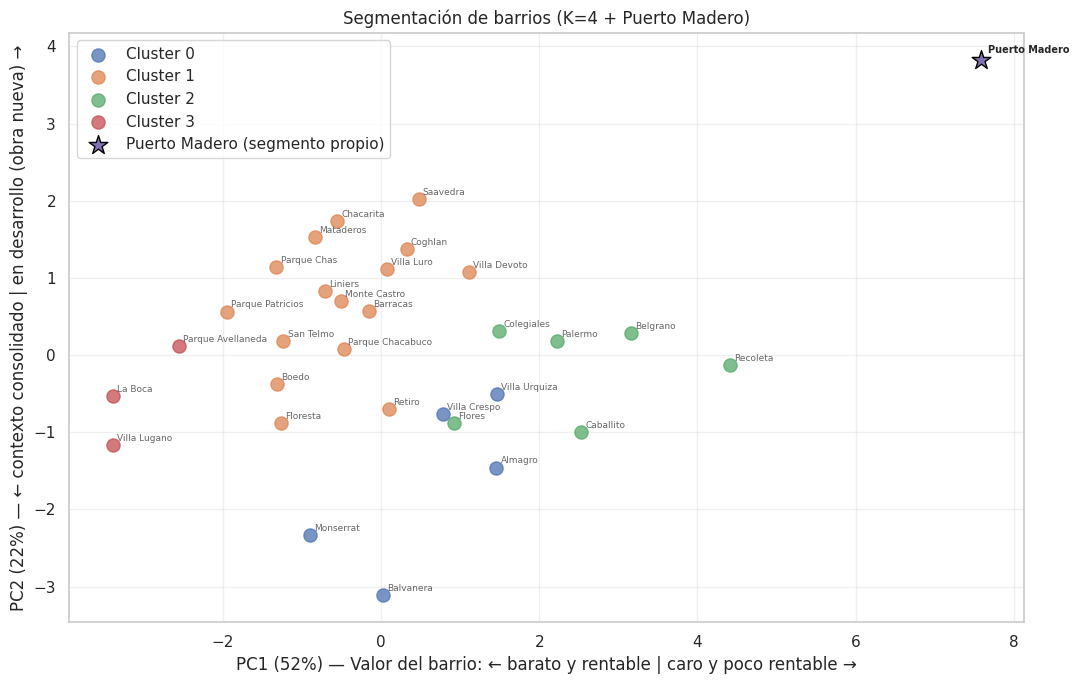

In [37]:
# --- Graficar los clusters sobre las 2 primeras componentes ---
# (incluye Puerto Madero, proyectado en el mismo espacio PCA)
pm_pca = pca.transform(StandardScaler().fit(perfil_30[VARS]).transform(pm_fila[VARS]))

fig, ax = plt.subplots(figsize=(11, 7))
colores = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
for c in range(4):
    mask = km_final.labels_ == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=90, alpha=0.75,
               color=colores[c], label=f"Cluster {c}")
# Puerto Madero
ax.scatter(pm_pca[0, 0], pm_pca[0, 1], s=200, marker="*",
           color=colores[4], label="Puerto Madero (segmento propio)", edgecolor="black")

# Etiquetar barrios
for barrio, fila in perfil_30.iterrows():
    idx = perfil_30.index.get_loc(barrio)
    ax.annotate(barrio, (X_pca[idx, 0], X_pca[idx, 1]),
                fontsize=6.5, alpha=0.7, xytext=(3, 3), textcoords="offset points")
ax.annotate("Puerto Madero", (pm_pca[0, 0], pm_pca[0, 1]),
            fontsize=7, fontweight="bold", xytext=(5, 5), textcoords="offset points")

# Ejes con etiqueta interpretativa
ax.set_xlabel(f"PC1 ({var_exp[0]*100:.0f}%) — Valor del barrio: ← barato y rentable | caro y poco rentable →")
ax.set_ylabel(f"PC2 ({var_exp[1]*100:.0f}%) — ← contexto consolidado | en desarrollo (obra nueva) →")
ax.set_title("Segmentación de barrios (K=4 + Puerto Madero)")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### Un caso de frontera: ¿por qué Flores está en el Cluster 2?

En el gráfico, **Flores** parece estar más cerca del Cluster 0 que del Cluster 2, al que fue asignado.
Esto ilustra la advertencia hecha sobre el PCA: el clustering se calcula en **3 componentes**, pero el
gráfico solo muestra **2** (PC1 y PC2). Flores se ve cercano al Cluster 0 en este plano, pero en la
tercera componente —no visible— está más próximo al Cluster 2, y el algoritmo (que sí usa las 3
dimensiones) lo agrupa en consecuencia.

Se verifica calculando la **distancia real de Flores a cada centro de cluster** en el espacio completo
de 3 componentes: la menor distancia confirma la asignación. De todos modos, Flores es un **caso de
frontera** (su contexto medio-bajo lo acerca al Cluster 2, pero comparte alta densidad de oferta con el
0), lo que es esperable: en todo clustering hay barrios limítrofes que podrían reasignarse con cambios
menores.

In [38]:
# Comparar Flores con los centros de cada cluster (en el espacio de 3 componentes PCA)
flores_idx = perfil_30.index.get_loc("Flores")
flores_pca = X_clust_pca[flores_idx]
print(f"Flores en PCA (3 comp): {flores_pca.round(2)}")
print("\nDistancia de Flores a cada centro de cluster:")
for c in range(4):
    centro = X_clust_pca[km_final.labels_ == c].mean(axis=0)
    dist = np.linalg.norm(flores_pca - centro)
    print(f"  Cluster {c}: distancia = {dist:.2f}")

Flores en PCA (3 comp): [ 0.92 -0.88  1.12]

Distancia de Flores a cada centro de cluster:
  Cluster 0: distancia = 2.43
  Cluster 1: distancia = 2.48
  Cluster 2: distancia = 1.73
  Cluster 3: distancia = 4.06


### Interpretación de los perfiles

Cada cluster representa un **perfil de barrio** con una lógica de inversión distinta:

**Cluster 0 — "Céntricos consolidados" (Almagro, Balvanera, Monserrat, Villa Crespo, Villa Urquiza).**
Precio medio, pero el **mejor contexto de todos** (índice +0,9): mucho transporte, comercios y
seguridad relativa. Alta densidad de oferta (mercado líquido). Son barrios céntricos, establecidos,
donde se paga sobre todo por el entorno. Rentabilidad media (3,7%).

**Cluster 1 — "Intermedios de perfil medio" (16 barrios: Barracas, Boedo, Retiro, San Telmo…).**
El grupo más grande y heterogéneo. Precio y contexto medios, baja densidad de oferta (mercado más
chico). Rentabilidad algo superior a la media (3,9%). Es el "centro de gravedad" del mercado: barrios
sin un rasgo extremo, de oportunidad dispersa.

**Cluster 2 — "Premium de gran demanda" (Belgrano, Caballito, Colegiales, Flores, Palermo, Recoleta).**
El **precio más alto** (174k, sin contar Puerto Madero), propiedades **más grandes** (65 m²) y mucha
oferta. Pero la **rentabilidad más baja** (3,0%): se paga caro y rinde poco por alquiler. Son los
barrios "aspiracionales" del corredor norte: ideales para revalorización/reventa, poco atractivos para
renta.

**Cluster 3 — "Oportunidad de renta" (La Boca, Parque Avellaneda, Villa Lugano).**
El **precio más bajo** (70k) y la **rentabilidad más alta** (5,6%). Poca obra nueva (25%, mercado
consolidado-popular) y baja oferta. Son barrios del sur/oeste donde el alquiler rinde mejor en relación
al precio de compra. El perfil más atractivo para una **estrategia de renta**, con la contraparte de
mayor riesgo de contexto.

**Cluster 4 — "Segmento exclusivo" (Puerto Madero).**
Un barrio en sí mismo. Precio radicalmente superior (550k, 3x el premium), propiedades enormes (101 m²),
pero contexto pobre (−1,0) y rentabilidad baja (3,1%). Se valoriza por prestigio y exclusividad, no por
el entorno urbano ni por el rendimiento. No comparable con ningún otro segmento.

## 6. Score de atractivo de inversión

**Objetivo.** Integrar los tres análisis en una **única métrica de priorización** que rankee los
barrios por atractivo para el fondo. Es el producto final: convierte el diagnóstico (H1, H2, H3) en
una herramienta de decisión.

**Fórmula (definida en la PE1):**

> Score(b) = 0,45 · z-Rentabilidad + 0,40 · z-Oportunidad + 0,15 · z-Contexto

Cada componente se estandariza (z-score) para llevarlo a una escala común antes de ponderar. Los
pesos reflejan la prioridad del cliente: el **retorno** lidera (rentabilidad), la **oportunidad** es
el medio para lograrlo (pesa casi igual), y el **contexto** actúa como salvaguarda del entorno (menor
peso). Se declara como herramienta de **priorización**, no de predicción garantizada.

**Componentes:**
- **Rentabilidad (H2):** rentabilidad neta por alquiler del barrio.
- **Oportunidad (H1):** densidad de oportunidad = proporción de propiedades del barrio marcadas como
  subvaluadas por el modelo de valor esperado.
- **Contexto (H3):** índice de contexto (transporte, seguridad, comercios).

In [39]:
# --- Componente OPORTUNIDAD: densidad de propiedades subvaluadas por barrio ---
# 'candidatas' son las propiedades subvaluadas (residuo <= umbral) de H1
total_x_barrio = usados.groupby("barrio").size().rename("n_total")
cand_x_barrio = candidatas.groupby("barrio").size().rename("n_candidatas")
densidad_op = (cand_x_barrio / total_x_barrio).fillna(0).rename("densidad_oportunidad") * 100

# --- Armar la tabla del Score: unir los 3 componentes por barrio ---
score_df = (rent[["rent_neta_%"]]
            .join(ctx.set_index("nombre")["indice_contexto"])
            .join(densidad_op))
score_df = score_df.dropna(subset=["rent_neta_%", "indice_contexto"])
score_df["densidad_oportunidad"] = score_df["densidad_oportunidad"].fillna(0)

# --- Estandarizar cada componente (z-score) ---
def z(s): return (s - s.mean()) / s.std()
score_df["z_rentabilidad"] = z(score_df["rent_neta_%"])
score_df["z_oportunidad"]  = z(score_df["densidad_oportunidad"])
score_df["z_contexto"]     = z(score_df["indice_contexto"])

# --- Score final (pesos PE1) ---
score_df["score"] = (0.45 * score_df["z_rentabilidad"]
                     + 0.40 * score_df["z_oportunidad"]
                     + 0.15 * score_df["z_contexto"])

print(f"Barrios con Score: {len(score_df)}")
print("\nTop 10 barrios por atractivo de inversión:")
print(score_df.sort_values("score", ascending=False)
      [["rent_neta_%", "densidad_oportunidad", "indice_contexto", "score"]]
      .head(10).round(2).to_string())
print("\nBottom 5:")
print(score_df.sort_values("score")[["score"]].head(5).round(2).to_string())o

Barrios con Score: 31

Top 10 barrios por atractivo de inversión:
                   rent_neta_%  densidad_oportunidad  indice_contexto  score
barrio                                                                      
Villa Lugano              6.50                 14.79            -0.32   1.65
Retiro                    4.04                 24.01             0.07   1.15
Monserrat                 4.55                 13.31             0.94   0.90
La Boca                   5.58                  9.88            -0.50   0.75
San Telmo                 4.20                 17.14            -0.38   0.59
Parque Avellaneda         5.57                  6.47            -0.32   0.54
Mataderos                 4.58                 12.58            -0.41   0.44
Balvanera                 4.15                  8.30             1.19   0.40
Recoleta                  2.64                 20.53             0.52   0.29
Liniers                   4.19                 12.44            -0.24   0.28

Bottom 5:

### Del barrio a la propiedad: ranking de oportunidades individuales

El Score de barrio indica *dónde* buscar; para que la herramienta sea accionable, se baja a la
**propiedad individual**. Se parte de las **candidatas a subvaluación** (las propiedades con residuo
≤ −31% identificadas en H1, es decir, gangas reales) y se las ordena combinando dos factores
estandarizados:

> Score propiedad = z(subvaluación) + z(score del barrio)

Así, el top reúne propiedades que son **gangas reales** (desvío de precio significativo) **y** están en
**barrios atractivos** (buena rentabilidad, oportunidad y contexto). El atractivo del barrio funciona
como criterio de desempate entre gangas, sin rescatar propiedades que no lo son: toda propiedad del
ranking tiene, primero, un desvío de precio verificado.

In [40]:
# --- Score a nivel propiedad: solo candidatas subvaluadas, ordenadas por subvaluación + barrio ---
props = candidatas.copy()

# Traer el score del barrio a cada candidata
props = props.merge(score_df[["score"]].rename(columns={"score": "score_barrio"}),
                    left_on="barrio", right_index=True, how="inner")

# Score de propiedad: subvaluación (residuo negativo = mejor, por eso invertimos) + score del barrio
props["z_subvaluacion"] = -z(props["residuo_pct"])    # más subvaluada = mayor z
props["z_score_barrio"] = z(props["score_barrio"])
props["score_propiedad"] = props["z_subvaluacion"] + props["z_score_barrio"]

print(f"Candidatas con barrio en el Score: {len(props)}")
print()

# Top 30 propiedades
cols = ["direccion", "barrio", "m2_cubiertos", "ambientes", "precio_usd",
        "precio_m2", "precio_m2_esperado", "residuo_pct", "score_barrio", "score_propiedad"]
cols = [c for c in cols if c in props.columns]
print("TOP 30 OPORTUNIDADES (gangas en barrios atractivos):")
print(props.nlargest(30, "score_propiedad")[cols].round(1).to_string(index=False))

Candidatas con barrio en el Score: 1930

TOP 30 OPORTUNIDADES (gangas en barrios atractivos):
                                                                                                             direccion        barrio  m2_cubiertos  ambientes  precio_usd  precio_m2  precio_m2_esperado  residuo_pct  score_barrio  score_propiedad
                                                             Avenida Ingeniero Huergo 1191, San Telmo, Capital Federal     San Telmo         140.0          4    100000.0      714.3              2598.1        -72.5           0.6              5.4
                                                                     José León Suárez 2540, Mataderos, Capital Federal     Mataderos          45.0          2     22500.0      500.0              1926.1        -74.0           0.4              5.4
                                                         Pasaje 2 De Abril De 1982 6400, Villa Lugano, Capital Federal  Villa Lugano          93.0          5     49000.0  

In [41]:
# --- Ranking final de oportunidades: candidatas sin duplicados ---
props_unicas = props.drop_duplicates(subset=["direccion", "precio_usd", "m2_cubiertos"])
print(f"Candidatas: {len(props)}  ->  sin duplicados: {len(props_unicas)}")
print()

cols = ["direccion", "barrio", "m2_cubiertos", "ambientes", "precio_usd",
        "precio_m2", "precio_m2_esperado", "residuo_pct", "score_barrio", "score_propiedad"]
cols = [c for c in cols if c in props_unicas.columns]

print("TOP 30 OPORTUNIDADES (gangas en barrios atractivos, sin duplicados):")
print(props_unicas.nlargest(30, "score_propiedad")[cols].round(1).to_string(index=False))



Candidatas: 1930  ->  sin duplicados: 1911

TOP 30 OPORTUNIDADES (gangas en barrios atractivos, sin duplicados):
                                                                                                             direccion        barrio  m2_cubiertos  ambientes  precio_usd  precio_m2  precio_m2_esperado  residuo_pct  score_barrio  score_propiedad
                                                             Avenida Ingeniero Huergo 1191, San Telmo, Capital Federal     San Telmo         140.0          4    100000.0      714.3              2598.1        -72.5           0.6              5.4
                                                                     José León Suárez 2540, Mataderos, Capital Federal     Mataderos          45.0          2     22500.0      500.0              1926.1        -74.0           0.4              5.4
                                                         Pasaje 2 De Abril De 1982 6400, Villa Lugano, Capital Federal  Villa Lugano          93.0      

### Nota: casos de residuo extremo que requieren verificación

El ranking incluye algunas propiedades con un desvío de precio muy grande (residuo < −70%) que
**probablemente reflejan errores de publicación** más que oportunidades reales. Ejemplos: una
propiedad en Puerto Madero a ~909 USD/m² (esperado ~5.570) o en Recoleta a ~923 USD/m² (esperado
~3.420) —valores implausibles para esos barrios, compatibles con un dígito faltante, una cochera o
baulera mal clasificada, o un precio de alquiler cargado como venta—.

**Estas publicaciones se conservan en el ranking de forma deliberada**: el sistema las señala como
anomalías (su función es detectar desvíos), pero la decisión final exige **verificación individual**.
Esto ilustra el principio rector del proyecto: el modelo produce *señales* de oportunidad, no
*conclusiones* de compra. Confirmar una oportunidad requiere inspeccionar la publicación, validar el
estado real de la propiedad y sumar costos, liquidez y estrategia de salida.

## 7. Conclusiones del desarrollo analítico

Esta notebook llevó el proyecto de la exploración descriptiva (PE2) a un **sistema de decisión de
inversión validado**, respondiendo las tres hipótesis y materializando el producto final.

### Qué se validó

**H1 — Detección de subvaluación (confirmada como señal).** El modelo de valor esperado (regresión
lineal sobre precio/m², R² = 0,55 fuera de muestra) supera al baseline de mediana y permite estimar
el precio esperado de cada propiedad. Su residuo identifica **2.318 propiedades candidatas a
subvaluación**. Se validó la naturaleza de *señal* (no conclusión): el desvío puede reflejar
oportunidad real o factores no observados y errores de publicación, que requieren verificación.

**H2 — Rentabilidad premium vs. resto (confirmada).** Al calcular la rentabilidad **neta** (con
costos de transacción con fuente y costos recurrentes como supuestos declarados), los barrios premium
rinden 2,98% frente a 3,77% del resto —un 27% menos— con significancia estadística (Mann-Whitney
p = 0,0013). La estrategia de renta rinde comparativamente peor en los barrios caros.

**H3 — Contexto y precio (confirmada como asociación, no determinación).** Existe asociación positiva
y significativa entre contexto y precio/m² (Spearman rho = 0,41–0,53), pero acotada: el contexto
explica solo el 16–30% de la variación de precios. La seguridad es el componente dominante (+431
USD/m²). Puerto Madero —caro con mal contexto— es la prueba de que el precio puede desacoplarse del
entorno.

### Qué se descubrió

**Segmentación de mercado (clustering).** Los barrios se agrupan en **cinco perfiles** con lógicas de
inversión distintas: céntricos consolidados, intermedios, premium de gran demanda, oportunidad de
renta, y el segmento exclusivo de Puerto Madero. Esta tipología convierte 48 barrios dispersos en un
mapa accionable según la estrategia (renta vs. reventa).

**Hallazgos transversales.** La relación inversa precio–rentabilidad (H2) y la asociación
contexto–precio (H3) no son resultados aislados: reaparecen como los **ejes que estructuran todo el
mercado** (las dos primeras componentes del PCA). El análisis es internamente coherente.

### Qué entrega el sistema

El **Score de atractivo** integra las tres dimensiones (rentabilidad 0,45 + oportunidad 0,40 +
contexto 0,15) en dos niveles:
- **Por barrio:** un ranking que indica *dónde* buscar (top: Villa Lugano, Retiro, Monserrat).
- **Por propiedad:** un ranking de oportunidades concretas —con dirección— que combina subvaluación
  individual y atractivo del barrio, respondiendo *qué* comprar.

Esto cierra la brecha señalada en etapas previas: el proyecto pasa del análisis agregado por barrio a
una **recomendación accionable sobre propiedades individuales**.

### Limitaciones

- El modelo de valor esperado explica la mitad de la variación del precio/m²; el resto depende de
  atributos no capturados (estado, orientación, piso), por lo que el residuo es una señal a verificar.
- La rentabilidad y el contexto se calculan a nivel barrio, sobre ~31 barrios con datos suficientes de
  venta y alquiler; los barrios con poca oferta quedan fuera.
- Los costos recurrentes y algunos parámetros son supuestos declarados, no valores específicos del
  inversor.
- El sistema produce **señales de priorización, no garantías**: la decisión final requiere verificación
  individual, análisis de costos, liquidez y estrategia de salida.

### Del análisis a la herramienta

Los resultados —el ranking de oportunidades y la segmentación de barrios— constituyen la base del
**dashboard interactivo**, que permitirá al fondo explorar las recomendaciones según sus criterios
(barrio, presupuesto, estrategia).